# Book Market Analytics: Books to Scrape
**Data Science 500 Assignment**

**Name:** *your name* &nbsp;&nbsp; **Student ITS No:** *your number*

---
## Project Overview
This notebook documents a complete data science pipeline for the Books to Scrape catalogue (https://books.toscrape.com):

1. Data acquisition (web scraping with BeautifulSoup)
2. Data cleaning and preparation
3. Data visualisation and exploration
4. Predictive modelling (linear regression)
5. Interpretation, limitations and recommendations

**How to run:** Run the cells from top to bottom (Kernel > Restart & Run All). The scrape takes about 10 to 15 minutes. After the first run, the notebook reuses `books_raw.csv` instead of scraping again.

**Required libraries:** requests, beautifulsoup4, pandas, numpy, matplotlib, seaborn, scikit-learn.

## 0. Setup
Import the libraries and define the base URL. A descriptive user-agent is sent with every request.

In [1]:
import os
import re
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from urllib.parse import urljoin

BASE_URL = "https://books.toscrape.com/catalogue/"
HEADERS = {"User-Agent": "Mozilla/5.0 (Data Science 500 student project)"}

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

## 1. Data Acquisition (Web Scraping)
**Approach:** The catalogue has 50 listing pages of 20 books each.
- *Listing pages* give the title, price, star rating (as a word), availability and a link to the book.
- *Detail pages* give the genre (breadcrumb), description, UPC, number of reviews and stock quantity.

Good scraping practice is followed: a user-agent header, a short delay between requests, and error handling so one failed page does not stop the scrape. The raw data is saved to `books_raw.csv`.

In [2]:
def get_soup(url):
    resp = requests.get(url, headers=HEADERS, timeout=15)
    resp.raise_for_status()
    resp.encoding = "utf-8"
    return BeautifulSoup(resp.text, "html.parser")

def parse_listing_page(soup):
    books = []
    for art in soup.select("article.product_pod"):
        books.append({
            "title": art.h3.a["title"],
            "price_raw": art.select_one("p.price_color").text.strip(),
            "rating_word": art.select_one("p.star-rating")["class"][1],
            "availability_raw": art.select_one(
                "p.availability").get_text(strip=True),
            "detail_url": urljoin(BASE_URL, art.h3.a["href"]),
        })
    return books

def parse_detail_page(url):
    soup = get_soup(url)
    crumbs = soup.select("ul.breadcrumb li a")
    genre = crumbs[2].text.strip() if len(crumbs) > 2 else None

    desc_tag = soup.select_one("#product_description")
    description = None
    if desc_tag is not None:
        description = desc_tag.find_next_sibling("p").get_text(strip=True)

    table = {row.th.text.strip(): row.td.text.strip()
             for row in soup.select("table.table-striped tr")}
    return {
        "genre": genre,
        "description": description,
        "upc": table.get("UPC"),
        "num_reviews": table.get("Number of reviews"),
        "availability_detail": soup.select_one(
            "p.availability").get_text(strip=True),
    }

def scrape_catalogue(max_pages=50, delay=0.3):
    rows = []
    for page in range(1, max_pages + 1):
        try:
            soup = get_soup(f"{BASE_URL}page-{page}.html")
        except requests.HTTPError:
            break
        for book in parse_listing_page(soup):
            try:
                book.update(parse_detail_page(book["detail_url"]))
            except Exception as err:
                print("Skipped:", book["title"], "-", err)
            rows.append(book)
            time.sleep(delay)
        print(f"Page {page} done - {len(rows)} books collected")
    return pd.DataFrame(rows)

if os.path.exists("books_raw.csv"):
    raw_df = pd.read_csv("books_raw.csv")
    print("Loaded existing books_raw.csv")
else:
    raw_df = scrape_catalogue()
    raw_df.to_csv("books_raw.csv", index=False)
print(raw_df.shape)
raw_df.head()

Page 1 done - 20 books collected
Page 2 done - 40 books collected
Page 3 done - 60 books collected
Page 4 done - 80 books collected
Page 5 done - 100 books collected
Page 6 done - 120 books collected
Page 7 done - 140 books collected
Page 8 done - 160 books collected
Page 9 done - 180 books collected
Page 10 done - 200 books collected
Page 11 done - 220 books collected
Page 12 done - 240 books collected
Page 13 done - 260 books collected
Page 14 done - 280 books collected
Page 15 done - 300 books collected
Page 16 done - 320 books collected
Page 17 done - 340 books collected
Page 18 done - 360 books collected
Page 19 done - 380 books collected
Page 20 done - 400 books collected
Page 21 done - 420 books collected
Page 22 done - 440 books collected
Page 23 done - 460 books collected
Page 24 done - 480 books collected
Page 25 done - 500 books collected
Page 26 done - 520 books collected
Page 27 done - 540 books collected
Page 28 done - 560 books collected
Page 29 done - 580 books collecte

,title,price_raw,rating_word,availability_raw,detail_url,genre,description,upc,num_reviews,availability_detail
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,0,In stock (22 available)
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,0,In stock (20 available)
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,0,In stock (20 available)
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,0,In stock (20 available)
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,0,In stock (20 available)


### Acquisition summary
*Write here:* how many books were collected, how many genres, and any pages that were skipped.

## 2. Data Cleaning and Preparation
**Cleaning decisions:**
- **Price** is text such as "£51.77": extract the number and convert to float.
- **Rating** is a word: map One to Five onto 1 to 5.
- **Availability** is a sentence: split into an `in_stock` flag and a numeric `stock_qty`.
- **Missing descriptions:** keep the rows (they still have valid price and rating data), fill with an empty string and add a `has_description` flag.
- **Text fields:** trim, normalise whitespace, lower-case and strip punctuation for analysis.
- **Duplicates:** removed using the UPC.
- **Outliers:** flagged with the 1.5 x IQR rule but kept, because expensive books are real products.
- **Tags:** the site does not publish tags, so genre and description are used as the text-based descriptors.

In [3]:
df = pd.read_csv("books_raw.csv")
print("Raw shape:", df.shape)
print(df.isna().sum())

df = df.drop_duplicates(subset=["upc"]).reset_index(drop=True)

df["price_gbp"] = df["price_raw"].str.extract(r"(\d+\.\d+)")[0].astype(float)

rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df["rating_num"] = df["rating_word"].map(rating_map)

df["in_stock"] = (df["availability_detail"]
                  .str.contains("In stock", case=False).astype(int))
df["stock_qty"] = (df["availability_detail"]
                   .str.extract(r"\((\d+) available\)")[0]
                   .astype(float).fillna(0).astype(int))

df["num_reviews"] = (pd.to_numeric(df["num_reviews"], errors="coerce")
                     .fillna(0).astype(int))

df["description"] = (df["description"].fillna("")
                     .str.replace(r"\s+", " ", regex=True).str.strip())
df["has_description"] = (df["description"] != "").astype(int)
df["desc_clean"] = (df["description"].str.lower()
                    .str.replace(r"[^a-z\s]", " ", regex=True)
                    .str.replace(r"\s+", " ", regex=True).str.strip())
df["desc_word_count"] = df["desc_clean"].str.split().str.len()
df["title_word_count"] = df["title"].str.split().str.len()

df["genre"] = df["genre"].fillna("Unknown").str.strip()

assert df["price_gbp"].gt(0).all(), "Non-positive price found"
assert df["rating_num"].between(1, 5).all(), "Rating out of range"
assert df["rating_num"].notna().all(), "Unmapped rating"

q1, q3 = df["price_gbp"].quantile([0.25, 0.75])
iqr = q3 - q1
df["price_outlier"] = ~df["price_gbp"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print("Price outliers flagged:", df["price_outlier"].sum())

final_cols = ["title", "upc", "genre", "price_gbp", "rating_word",
              "rating_num", "in_stock", "stock_qty", "num_reviews",
              "has_description", "desc_word_count", "title_word_count",
              "price_outlier", "description", "desc_clean"]
df[final_cols].to_csv("books_clean.csv", index=False)
print("Clean shape:", df[final_cols].shape)
df[final_cols].describe(include="all").T

Raw shape: (1000, 10)
title                  0
price_raw              0
rating_word            0
availability_raw       0
detail_url             0
genre                  0
description            2
upc                    0
num_reviews            0
availability_detail    0
dtype: int64
Price outliers flagged: 0
Clean shape: (1000, 15)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,1000,999,The Star-Touched Queen,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
upc,1000,1000,a897fe39b1053632,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,1000,50,Default,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_gbp,1000.0,NaN,NaN,NaN,35.07035,14.44669,10.0,22.1075,35.98,47.4575,59.99
rating_word,1000,5,One,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating_num,1000.0,NaN,NaN,NaN,2.923,1.434967,1.0,2.0,3.0,4.0,5.0
in_stock,1000.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
stock_qty,1000.0,NaN,NaN,NaN,8.585,5.654622,1.0,3.0,7.0,14.0,22.0
num_reviews,1000.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_description,1000.0,NaN,NaN,NaN,0.998,0.044699,0.0,1.0,1.0,1.0,1.0


### Cleaning summary
*Write here:* final number of rows and columns, number of missing descriptions, number of price outliers flagged, and any other inconsistencies you found.

## 3. Data Visualisation and Exploration
The figures below examine price distribution, ratings, genre differences and the relationships between numeric variables. Each figure is saved as a PNG for the report.

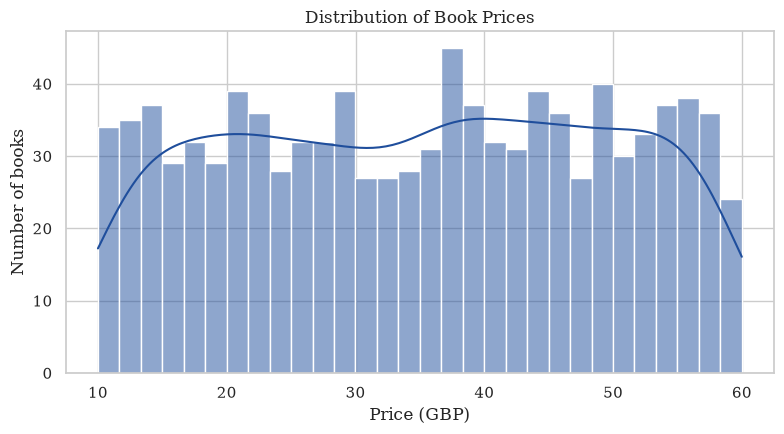

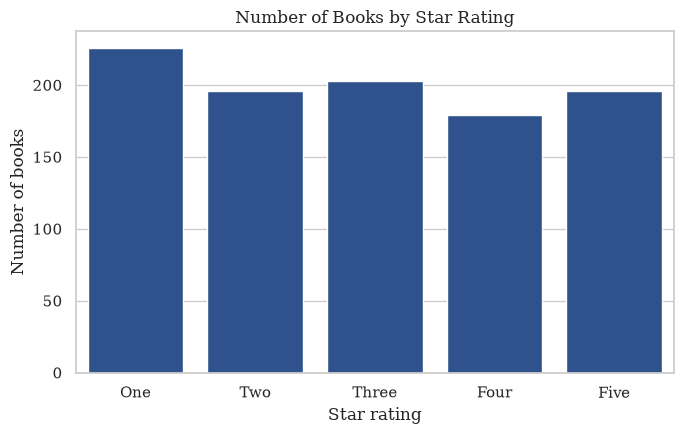

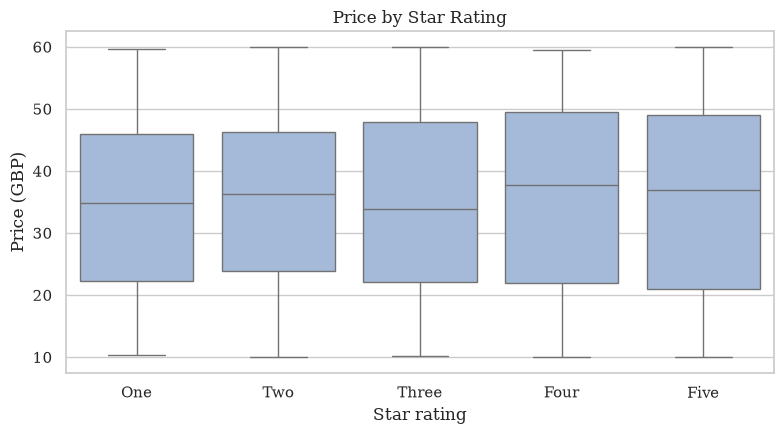

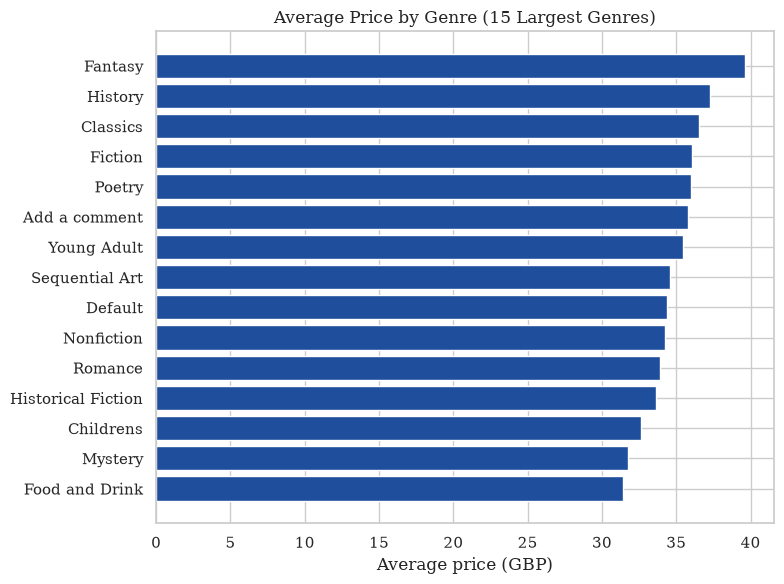

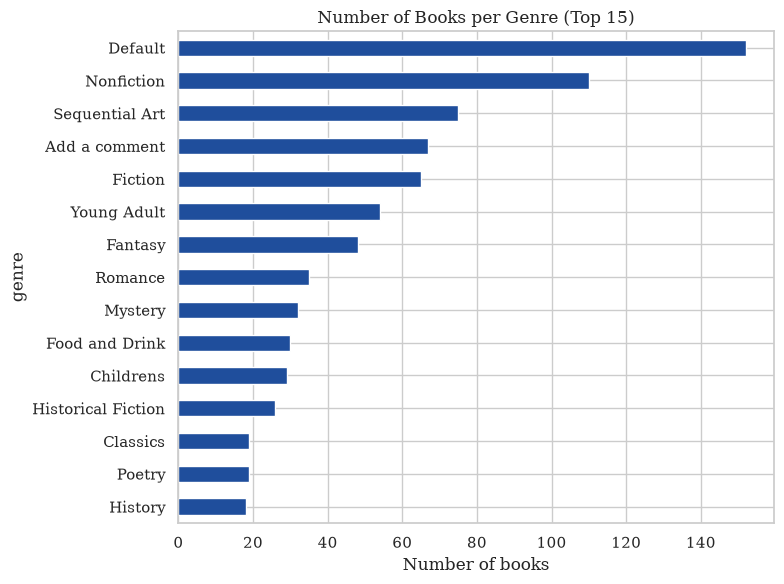

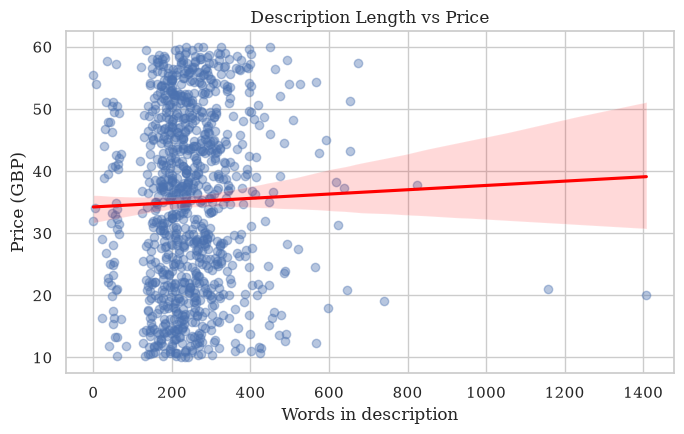

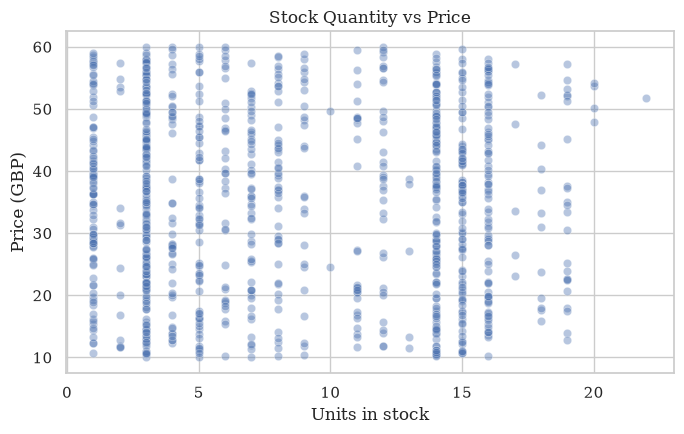

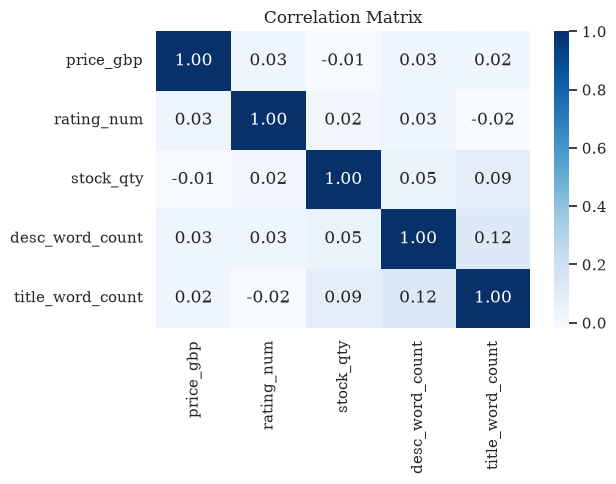

                  mean  median  count
rating_word                          
Five         35.374490  36.900    196
Four         36.093296  37.800    179
One          34.561195  34.770    226
Three        34.692020  33.780    203
Two          34.810918  36.215    196
                         mean  count
genre                               
Fantasy             39.593958     48
History             37.295000     18
Classics            36.545263     19
Fiction             36.066615     65
Poetry              35.974211     19
Add a comment       35.796418     67
Young Adult         35.449074     54
Sequential Art      34.572267     75
Default             34.392697    152
Nonfiction          34.260182    110
Romance             33.933714     35
Historical Fiction  33.644231     26
Childrens           32.638276     29
Mystery             31.719062     32
Food and Drink      31.414667     30


In [4]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "serif"

plt.figure(figsize=(8, 4.5))
sns.histplot(df["price_gbp"], bins=30, kde=True, color="#1f4e9c")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)"); plt.ylabel("Number of books")
plt.tight_layout(); plt.savefig("fig1_price_dist.png", dpi=200); plt.show()

order = ["One", "Two", "Three", "Four", "Five"]
plt.figure(figsize=(7, 4.5))
sns.countplot(data=df, x="rating_word", order=order, color="#1f4e9c")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star rating"); plt.ylabel("Number of books")
plt.tight_layout(); plt.savefig("fig2_rating_counts.png", dpi=200); plt.show()

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="rating_word", y="price_gbp", order=order,
            color="#9db8e0")
plt.title("Price by Star Rating")
plt.xlabel("Star rating"); plt.ylabel("Price (GBP)")
plt.tight_layout(); plt.savefig("fig3_price_by_rating.png", dpi=200); plt.show()

top15 = df["genre"].value_counts().head(15).index
genre_stats = (df[df["genre"].isin(top15)].groupby("genre")["price_gbp"]
               .agg(["mean", "count"]).sort_values("mean"))
plt.figure(figsize=(8, 6))
plt.barh(genre_stats.index, genre_stats["mean"], color="#1f4e9c")
plt.title("Average Price by Genre (15 Largest Genres)")
plt.xlabel("Average price (GBP)")
plt.tight_layout(); plt.savefig("fig4_price_by_genre.png", dpi=200); plt.show()

plt.figure(figsize=(8, 6))
df["genre"].value_counts().head(15).sort_values().plot.barh(color="#1f4e9c")
plt.title("Number of Books per Genre (Top 15)")
plt.xlabel("Number of books")
plt.tight_layout(); plt.savefig("fig5_genre_counts.png", dpi=200); plt.show()

plt.figure(figsize=(7, 4.5))
sns.regplot(data=df, x="desc_word_count", y="price_gbp",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Description Length vs Price")
plt.xlabel("Words in description"); plt.ylabel("Price (GBP)")
plt.tight_layout(); plt.savefig("fig6_desc_vs_price.png", dpi=200); plt.show()

plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=df, x="stock_qty", y="price_gbp", alpha=0.4)
plt.title("Stock Quantity vs Price")
plt.xlabel("Units in stock"); plt.ylabel("Price (GBP)")
plt.tight_layout(); plt.savefig("fig7_stock_vs_price.png", dpi=200); plt.show()

num_cols = ["price_gbp", "rating_num", "stock_qty",
            "desc_word_count", "title_word_count"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation Matrix")
plt.tight_layout(); plt.savefig("fig8_correlation.png", dpi=200); plt.show()

print(df.groupby("rating_word")["price_gbp"].agg(["mean", "median", "count"]))
print(genre_stats.sort_values("mean", ascending=False))

### Interpretation of the visualisations
Replace the prompts below with your own findings after running the cells above.

- **Price distribution (Fig 1):** range, mean, median and shape.
- **Ratings (Figs 2 and 3):** most common rating; does price rise, fall or stay flat with rating?
- **Genres (Figs 4 and 5):** most and least expensive genres; note that small genres give unstable averages.
- **Relationships (Figs 6 to 8):** strongest correlation with price; which variables show little or no association?

## 4. Predictive Modelling (Linear Regression)
**Target:** `price_gbp`

**Features and justification:**
- `rating_num`: perceived quality may relate to price.
- `stock_qty`: stock depth may reflect demand or pricing strategy.
- `desc_word_count`, `title_word_count`: proxies for marketing effort and title type.
- `genre` (top 10 genres plus "Other"), one-hot encoded with the first category dropped to avoid the dummy-variable trap.

Constant columns (such as `in_stock` and `num_reviews`) are dropped automatically. An 80/20 train-test split with a fixed seed is used, plus 5-fold cross-validation and a mean-price baseline for comparison.

Predictors used: ['rating_num', 'stock_qty', 'desc_word_count', 'title_word_count', 'genre_grouped_Default', 'genre_grouped_Fantasy', 'genre_grouped_Fiction', 'genre_grouped_Food and Drink', 'genre_grouped_Mystery', 'genre_grouped_Nonfiction', 'genre_grouped_Other', 'genre_grouped_Romance', 'genre_grouped_Sequential Art', 'genre_grouped_Young Adult']
                   Model     MAE    RMSE     R2
0      Linear Regression  12.704  14.671 -0.025
1  Baseline (mean price)  12.662  14.530 -0.005
CV R2 : -0.025 (+/- 0.016)
CV MAE: 12.609 (+/- 0.237)
Intercept: 33.606
                     feature  coefficient
       genre_grouped_Mystery       -6.894
genre_grouped_Food and Drink       -4.719
    genre_grouped_Nonfiction       -4.022
       genre_grouped_Fantasy        2.425
       genre_grouped_Default       -2.395
       genre_grouped_Romance       -2.349
   genre_grouped_Young Adult       -1.898
         genre_grouped_Other       -1.864
genre_grouped_Sequential Art       -1.787
       genr

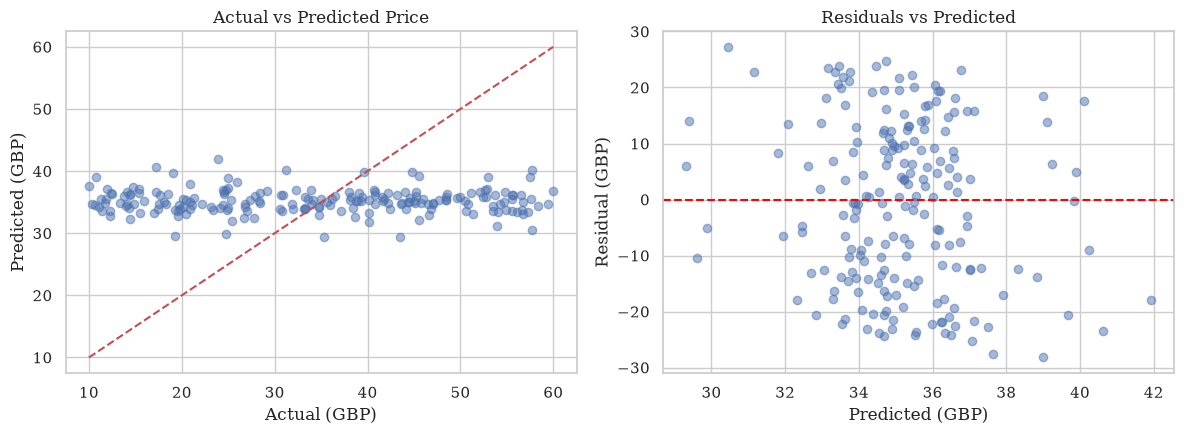

In [5]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

top_genres = df["genre"].value_counts().head(10).index
df["genre_grouped"] = np.where(df["genre"].isin(top_genres),
                               df["genre"], "Other")

features = ["rating_num", "stock_qty", "desc_word_count",
            "title_word_count", "genre_grouped"]
X = pd.get_dummies(df[features], columns=["genre_grouped"], drop_first=True)
X = X.astype(float)
X = X.loc[:, X.nunique() > 1]
y = df["price_gbp"]
print("Predictors used:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

def evaluate(name, mdl):
    pred = mdl.predict(X_test)
    return {"Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)}

results = pd.DataFrame([evaluate("Linear Regression", model),
                        evaluate("Baseline (mean price)", baseline)])
print(results.round(3))

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
cv_mae = -cross_val_score(LinearRegression(), X, y, cv=kf,
                          scoring="neg_mean_absolute_error")
print(f"CV R2 : {cv_r2.mean():.3f} (+/- {cv_r2.std():.3f})")
print(f"CV MAE: {cv_mae.mean():.3f} (+/- {cv_mae.std():.3f})")

coefs = (pd.DataFrame({"feature": X.columns, "coefficient": model.coef_})
         .sort_values("coefficient", key=abs, ascending=False))
print("Intercept:", round(model.intercept_, 3))
print(coefs.round(3).to_string(index=False))

pred = model.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=0.5)
lims = [y.min(), y.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_title("Actual vs Predicted Price")
ax[0].set_xlabel("Actual (GBP)"); ax[0].set_ylabel("Predicted (GBP)")
ax[1].scatter(pred, y_test - pred, alpha=0.5)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("Residuals vs Predicted")
ax[1].set_xlabel("Predicted (GBP)"); ax[1].set_ylabel("Residual (GBP)")
plt.tight_layout(); plt.savefig("fig9_model_diagnostics.png", dpi=200)
plt.show()

## 5. Interpretation, Limitations and Recommendations
### Model results
*Write here:* MAE, RMSE and R-squared for the model and the baseline, the cross-validation scores, and the largest coefficients explained in plain language (for example, "each extra star changes price by X pounds, holding other variables constant").

### Limitations
- Books to Scrape is a practice website, so its prices and ratings may not follow real market behaviour. Weak relationships are expected and do not necessarily mean the method is flawed.
- Real drivers of price (author, publisher, format, page count, publication date) are not available.
- Linear regression assumes linearity, constant error variance and independent errors; check the residual plot.
- Some genres have few books, so their coefficients are imprecise.
- The model shows association, not causation.

### Recommendations
- **Retailers:** use genre-level price benchmarks when pricing new titles; do not assume high ratings justify a premium without testing.
- **Publishers:** position new releases against their genre's typical price range; collect more attributes to improve future models.
- **Book buyers:** compare a book's price with its genre average; treat model predictions as a rough guide only.

*Adjust these to match your actual results.*

## 6. Conclusion
*Write here:* a short summary of what was scraped, how it was cleaned, the main insight from the visualisations, how well the model performed, and what should be done next (richer features, text mining of descriptions, regularised and non-linear models).